# Nutrimouse: building clustering ensembles as executable graphs

This notebook revisits [the original Nutrimouse example](Nutrimouse.ipynb) using
Pyrea's new graph API. The same 40 mice have two views: 120 gene-expression
measurements and 21 lipid measurements. We will build our own topologies,
inspect their NetworkX graphs, and evaluate the resulting partitions.

You will learn to:

1. Connect executable blocks using symbolic inputs.
2. Write a reusable `nn.Module` with a `forward()` method.
3. Stack fusion stages, share intermediate results, and merge branches of different depths.
4. Add a custom preprocessing block and adapt a scikit-learn estimator.
5. Use Parea 1 and Parea 2 graph builders, and spectral clustering with affinities.
6. Traverse the workflow and optimize clustering methods and hyperparameters with a genetic algorithm.

Graph nodes represent **operations in the ensemble workflow**. The matrices
carried between operations describe relationships between mice.

## 1. Install the development checkout

From the repository root, in your Python environment:

```bash
python -m pip install -e .
python -m pip install -r notebooks/requirements.txt
jupyter lab notebooks/Nutrimouse_Graphs.ipynb
```

Select the kernel for that environment and use **Restart Kernel and Run All**.
The CSV data are bundled under `notebooks/data/nutrimouse/`; execution does not
need a data download or `mvlearn`. See the [data provenance](data/nutrimouse/README.md)
for the source release, checksums, references, and attribution.

The examples use Python fusion methods. The original notebook's genetic helpers
and HCfused are not used. We standardize each view here, so these results are not
an exact reproduction of the original notebook or the paper's reported scores.

In [1]:
%matplotlib inline

from pathlib import Path
import importlib.metadata

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_mutual_info_score,
    normalized_mutual_info_score,
    pairwise_distances,
    silhouette_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler

from pyrea import models, nn, optim

SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

versions = {name: importlib.metadata.version(name)
            for name in ['pyrea', 'numpy', 'scikit-learn', 'networkx', 'matplotlib']}
display(pd.Series(versions, name='Version'))

pyrea           1.0.12
numpy           1.26.4
scikit-learn     1.3.2
networkx         3.6.1
matplotlib      3.11.2
Name: Version, dtype: object

## 2. Load aligned views and evaluation labels

The CSV rows have the same ordering as `mvlearn.datasets.load_nutrimouse()`.
We assign row-based IDs (`mouse_00`, etc.) to make that alignment visible.
These are convenience IDs, not original biological identifiers.

`genotype` has two classes and `diet` has five. We will pass neither annotation
to the models or the parameter-search objective. Genotype labels are used only
for the final NMI/AMI evaluation, as in the reference notebook.

In [2]:
project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'notebooks/data/nutrimouse/gene.csv').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Open this notebook from within the Pyrea repository checkout.')

data_dir = project_root / 'notebooks/data/nutrimouse'
gene = pd.read_csv(data_dir / 'gene.csv')
lipid = pd.read_csv(data_dir / 'lipid.csv')
genotype = pd.read_csv(data_dir / 'genotype.csv')['genotype']
diet = pd.read_csv(data_dir / 'diet.csv')['diet']

assert gene.shape == (40, 120) and lipid.shape == (40, 21)
assert len(genotype) == len(diet) == len(gene)
assert genotype.nunique() == 2 and diet.nunique() == 5
assert np.isfinite(gene.to_numpy()).all() and np.isfinite(lipid.to_numpy()).all()

sample_ids = pd.Index(['mouse_{:02d}'.format(i) for i in range(len(gene))], name='sample')
gene.index = lipid.index = sample_ids
genotype.index = diet.index = sample_ids
inputs = {'gene': gene, 'lipid': lipid}

display(pd.DataFrame({'samples': [len(gene), len(lipid)],
                      'features': [gene.shape[1], lipid.shape[1]]}, index=['gene', 'lipid']))
display(pd.crosstab(genotype, diet))

,samples,features
gene,40,120
lipid,40,21


diet,coc,fish,lin,ref,sun
genotype,,,,,
ppar,4,4,4,4,4
wt,4,4,4,4,4


### A quick look at the two views

These are separate PCA projections after per-feature standardization. Genotype
coloring is descriptive; it is not an input to clustering or parameter selection.
The different feature spaces need not show the same separation.

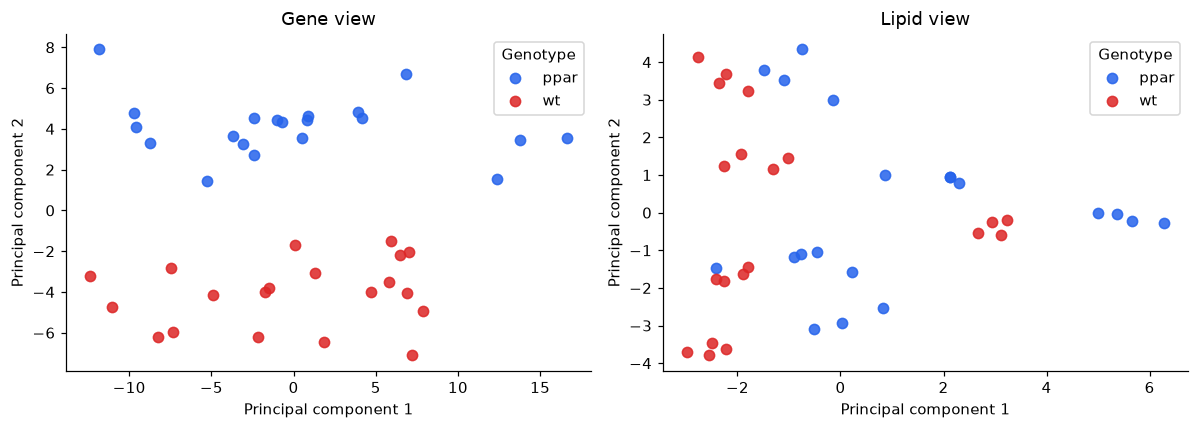

In [3]:
prepared_inputs = {
    name: pd.DataFrame(StandardScaler().fit_transform(frame),
                       index=frame.index, columns=frame.columns)
    for name, frame in inputs.items()
}
classes = sorted(genotype.unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, frame) in zip(axes, prepared_inputs.items()):
    embedding = PCA(n_components=2, svd_solver='full').fit_transform(frame)
    for label, color in zip(classes, ['#2563eb', '#dc2626']):
        mask = genotype.to_numpy() == label
        ax.scatter(embedding[mask, 0], embedding[mask, 1], label=label,
                   color=color, s=45, alpha=0.85)
    ax.set(title=name.capitalize() + ' view', xlabel='Principal component 1',
           ylabel='Principal component 2')
    ax.legend(title='Genotype')
fig.tight_layout()
plt.show()

## 3. Define a custom executable block

Subclass `nn.Block` for an indivisible operation. The declared kinds tell the
compiler what can connect to it. This block fits a fresh scaler on every call
and returns features in the same sample order; it retains no fitted state.

Clustering here is transductive: all 40 mice are analyzed together. This is not
a train/test preprocessing pipeline for predicting labels of unseen mice.

In [4]:
class Standardize(nn.Block):
    input_kinds = {'data': nn.FEATURES}
    output_kind = nn.FEATURES

    def __init__(self, name=None):
        self.name = name

    def forward(self, data):
        return StandardScaler().fit_transform(data)

## 4. Connect a graph directly

`nn.Input` is symbolic. Calling a block on it records a connection rather than
running clustering. We standardize and cluster each view, fuse the partitions
into a **distance** matrix, and recluster that matrix into two groups.

A graph can expose several named outputs. Keeping both labels and the fused
matrix makes later inspection and evaluation straightforward. The cluster counts
below are illustrative settings; a later example searches alternative settings.

In [5]:
gene_input, lipid_input = nn.Input('gene'), nn.Input('lipid')
gene_scaled = Standardize(name='gene_scale')(gene_input)
lipid_scaled = Standardize(name='lipid_scale')(lipid_input)
gene_labels = nn.Cluster('hierarchical', n_clusters=3, method='ward',
                         name='gene_cluster')(gene_scaled)
lipid_labels = nn.Cluster('hierarchical', n_clusters=3, method='complete',
                          name='lipid_cluster')(lipid_scaled)
fused_distance = nn.Fusion('disagreement', name='fusion')(gene_labels, lipid_labels)
final_labels = nn.Hierarchical(n_clusters=2, input_kind=nn.DISTANCE,
                              name='final')(fused_distance)

functional_graph = nn.Graph(inputs={'gene': gene_input, 'lipid': lipid_input},
                            outputs={'labels': final_labels, 'distance': fused_distance})
functional_result = functional_graph(**inputs)
assert functional_result['labels'].shape == (40,)
assert functional_result['distance'].shape == (40, 40)
assert np.allclose(functional_result['distance'], functional_result['distance'].T)
assert np.allclose(np.diag(functional_result['distance']), 0)
print('Final cluster sizes:', dict(zip(*np.unique(functional_result['labels'], return_counts=True))))

Final cluster sizes: {0: 21, 1: 19}


### Draw the executable topology

The helper below uses dependency depth for layout. Each box is an input or an
executable block; its color describes the kind of value it produces. We can use
the same helper for every custom or predefined topology in this notebook.

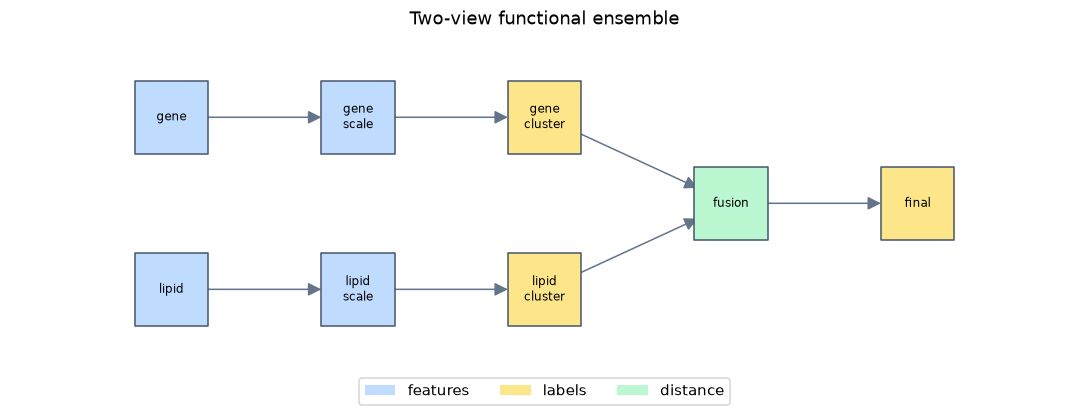

In [6]:
KIND_COLORS = {nn.FEATURES: '#bfdbfe', nn.LABELS: '#fde68a',
               nn.DISTANCE: '#bbf7d0', nn.AFFINITY: '#f5d0fe'}

def draw_workflow(model, title):
    topology = model.graph
    depth = {}
    for node in nx.topological_sort(topology):
        depth[node] = 1 + max((depth[parent] for parent in topology.predecessors(node)), default=-1)
    layers = {}
    for node, level in depth.items():
        layers.setdefault(level, []).append(node)
    positions = {node: (level, (len(nodes) - 1) / 2 - i)
                 for level, nodes in layers.items() for i, node in enumerate(nodes)}
    width = max(10, 2.0 * len(layers))
    height = max(3.8, 1.2 * max(map(len, layers.values())) + 1.5)
    fig, ax = plt.subplots(figsize=(width, height))
    colors = [KIND_COLORS[topology.nodes[node]['kind']] for node in topology]
    nx.draw_networkx_nodes(topology, positions, node_color=colors, node_shape='s',
                           node_size=2300, edgecolors='#475569', ax=ax)
    nx.draw_networkx_edges(topology, positions, node_size=2300, arrowsize=18,
                           arrowstyle='-|>', edge_color='#64748b', ax=ax)
    nx.draw_networkx_labels(topology, positions,
                            labels={node: node.replace('_', '\n').replace('.', '\n')
                                    for node in topology}, font_size=8, ax=ax)
    used_kinds = {attrs['kind'] for _, attrs in topology.nodes(data=True)}
    ax.legend(handles=[Patch(facecolor=color, label=kind)
                       for kind, color in KIND_COLORS.items() if kind in used_kinds],
              loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=len(used_kinds))
    ax.set_title(title, pad=18)
    ax.margins(x=0.15, y=0.3)
    ax.axis('off')
    fig.tight_layout()
    plt.show()

draw_workflow(functional_graph, 'Two-view functional ensemble')

## 5. Write the same topology as a reusable module

Define blocks in `__init__` and connect them in `forward()`. `compile()` infers
feature inputs from the required argument names and builds the NetworkX graph.
The block attribute names become parameter names, such as
`gene_cluster__method`. The module can also execute eagerly on arrays.

In [7]:
class NutrimouseEnsemble(nn.Module):
    def __init__(self, n_clusters=2):
        self.gene_scale = Standardize()
        self.lipid_scale = Standardize()
        self.gene_cluster = nn.Cluster('hierarchical', n_clusters=3, method='ward')
        self.lipid_cluster = nn.Cluster('hierarchical', n_clusters=3, method='complete')
        self.fusion = nn.Fusion('disagreement')
        self.final = nn.Hierarchical(n_clusters=n_clusters, input_kind=nn.DISTANCE)

    def forward(self, gene, lipid):
        gene_partition = self.gene_cluster(self.gene_scale(gene))
        lipid_partition = self.lipid_cluster(self.lipid_scale(lipid))
        distance = self.fusion(gene_partition, lipid_partition)
        return {'labels': self.final(distance), 'distance': distance}

module = NutrimouseEnsemble()
module_graph = module.compile()
module_result = module_graph(**inputs)
eager_result = module(gene.to_numpy(), lipid.to_numpy())
assert np.array_equal(module_result['labels'], functional_result['labels'])
assert np.array_equal(module_result['distance'], functional_result['distance'])
assert np.array_equal(module_result['labels'], eager_result['labels'])
display(pd.Series(module_graph.get_params(), name='Configuration'))

gene_cluster__clusterer      hierarchical
gene_cluster__n_clusters                3
gene_cluster__method                 ward
lipid_cluster__clusterer     hierarchical
lipid_cluster__n_clusters               3
lipid_cluster__method            complete
fusion__method               disagreement
fusion__normalize                   False
final__clusterer             hierarchical
final__n_clusters                       2
final__method                        ward
Name: Configuration, dtype: object

### Validate sample alignment

DataFrames let the executor check sample identifiers before any block executes.
Reversing just one view is rejected instead of silently combining different mice.
Bare NumPy arrays use positional alignment; you can attach identifiers explicitly
with `nn.SampleData(array, sample_ids)`.

In [8]:
try:
    module_graph(gene=gene, lipid=lipid.iloc[::-1])
except ValueError as error:
    print('Expected alignment error:', error)
else:
    raise AssertionError('Misaligned samples should have been rejected')

Expected alignment error: lipid sample identifiers/order do not match other inputs


## 6. Build a custom topology with unequal branch depths

We are not limited to Parea 1 or Parea 2. This graph uses a custom KMeans adapter,
two fusion stages, a shortcut from an early partition, and a strict-consensus
endpoint. The first fused matrix feeds two later blocks and is computed once per
run. The shortcut reaches the second fusion sooner than those deeper branches;
the executor still waits until **all** its dependencies are ready.

`nn.Function` wraps the KMeans callable. It constructs a fresh estimator per call
and fixes its random seed, rather than sharing fitted estimator state.

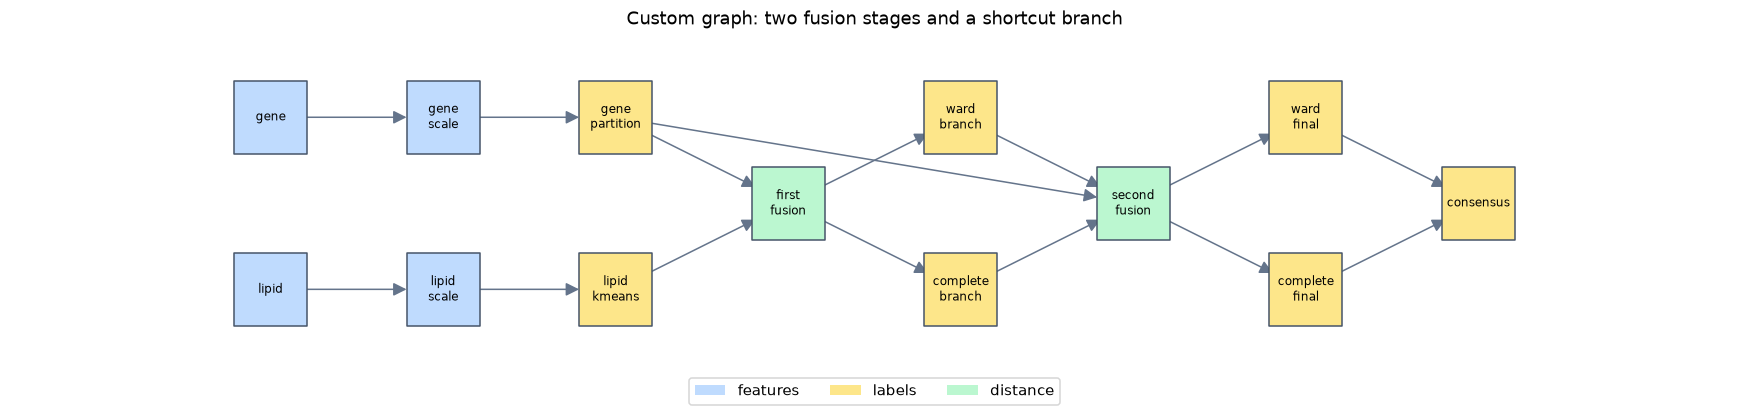

,node,kind,shape
0,gene,features,"(40, 120)"
1,lipid,features,"(40, 21)"
2,gene_scale,features,"(40, 120)"
3,lipid_scale,features,"(40, 21)"
4,gene_partition,labels,"(40,)"
5,lipid_kmeans,labels,"(40,)"
6,first_fusion,distance,"(40, 40)"
7,ward_branch,labels,"(40,)"
8,complete_branch,labels,"(40,)"
9,second_fusion,distance,"(40, 40)"


In [9]:
def kmeans_partition(data):
    return KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(data)

gene_source, lipid_source = nn.Input('gene'), nn.Input('lipid')
gene_features = Standardize(name='gene_scale')(gene_source)
lipid_features = Standardize(name='lipid_scale')(lipid_source)
early_gene = nn.Hierarchical(3, name='gene_partition')(gene_features)
early_lipid = nn.Function(kmeans_partition, {'data': nn.FEATURES},
                          output_kind=nn.LABELS, name='lipid_kmeans')(lipid_features)
first_distance = nn.Fusion(name='first_fusion')(early_gene, early_lipid)
ward_branch = nn.Hierarchical(3, method='ward', input_kind=nn.DISTANCE,
                             name='ward_branch')(first_distance)
complete_branch = nn.Hierarchical(4, method='complete', input_kind=nn.DISTANCE,
                                 name='complete_branch')(first_distance)
second_distance = nn.Fusion(name='second_fusion')(early_gene, ward_branch, complete_branch)
ward_final = nn.Hierarchical(2, method='ward', input_kind=nn.DISTANCE,
                            name='ward_final')(second_distance)
complete_final = nn.Hierarchical(3, method='complete', input_kind=nn.DISTANCE,
                                name='complete_final')(second_distance)
consensus = nn.Consensus(name='consensus')(ward_final, complete_final)
stacked_graph = nn.Graph(
    {'gene': gene_source, 'lipid': lipid_source},
    {'labels': consensus, 'distance': second_distance,
     'ward_labels': ward_final, 'complete_labels': complete_final},
)
stacked_result, intermediates = stacked_graph.run(inputs, return_intermediates=True)
draw_workflow(stacked_graph, 'Custom graph: two fusion stages and a shortcut branch')
display(pd.DataFrame([
    {'node': node, 'kind': stacked_graph.graph.nodes[node]['kind'], 'shape': value.shape}
    for node, value in intermediates.items()
]))

### Strict consensus and repeat execution

Two samples share a consensus cluster only if **every** final partition groups
them together. This is not majority voting. The common refinement can have more
clusters than either input. The output below reports the actual counts.

Intermediate results belong to one invocation. Calling the same graph again
recomputes its blocks; it does not append old partitions or reuse stale results.

In [10]:
same_consensus = stacked_result['labels'][:, None] == stacked_result['labels'][None, :]
for key in ['ward_labels', 'complete_labels']:
    same_input = stacked_result[key][:, None] == stacked_result[key][None, :]
    assert np.all(~same_consensus | same_input)
assert len(np.unique(stacked_result['labels'])) >= 3
assert np.array_equal(stacked_graph(**inputs)['labels'], stacked_result['labels'])
assert list(intermediates).count('first_fusion') == 1
print({key: len(np.unique(stacked_result[key]))
       for key in ['ward_labels', 'complete_labels', 'labels']})

{'ward_labels': 2, 'complete_labels': 3, 'labels': 4}


## 7. Traverse the workflow with NetworkX

Breadth-first search is useful for exploring reachability. It is not a general
execution schedule for merging branches of different lengths. Execution uses
topological order. Connections also retain their named input ports, so a custom
block's inputs do not depend on NetworkX neighbor ordering.

In [11]:
topology = stacked_graph.graph
bfs_order = list(nx.bfs_tree(topology, source='gene'))
execution_order = list(nx.topological_sort(topology))
assert nx.is_directed_acyclic_graph(topology)
assert all(execution_order.index(source) < execution_order.index(target)
           for source, target in topology.edges)
print('BFS from the gene input:', bfs_order)
print('Dependency order:', execution_order)
display(pd.DataFrame([
    {'source': source, 'destination': target, 'input_ports': ', '.join(attrs['ports'])}
    for source, target, attrs in topology.edges(data=True)
]))

BFS from the gene input: ['gene', 'gene_scale', 'gene_partition', 'second_fusion', 'first_fusion', 'ward_final', 'complete_final', 'ward_branch', 'complete_branch', 'consensus']
Dependency order: ['gene', 'lipid', 'gene_scale', 'lipid_scale', 'gene_partition', 'lipid_kmeans', 'first_fusion', 'ward_branch', 'complete_branch', 'second_fusion', 'ward_final', 'complete_final', 'consensus']


,source,destination,input_ports
0,second_fusion,ward_final,data
1,second_fusion,complete_final,data
2,ward_final,consensus,partitions[0]
3,complete_final,consensus,partitions[1]
4,gene_partition,second_fusion,partitions[0]
5,gene_partition,first_fusion,partitions[0]
6,ward_branch,second_fusion,partitions[1]
7,complete_branch,second_fusion,partitions[2]
8,gene_scale,gene_partition,data
9,first_fusion,ward_branch,data


## 8. Use the predefined Parea graph builders

The builders are convenience topologies over the same public blocks. Both accept
any positive number of views and use disagreement fusion. Here we apply the
same per-view standardization outside the builders; the custom graphs above
include that step inside their topology.

Parea 1 uses two method-specific branches. Parea 2 chooses an initial method per
view. `k_final=2` requests one final two-cluster solution instead of strict
consensus. `return_matrix=True` exposes the final distance matrix as well.

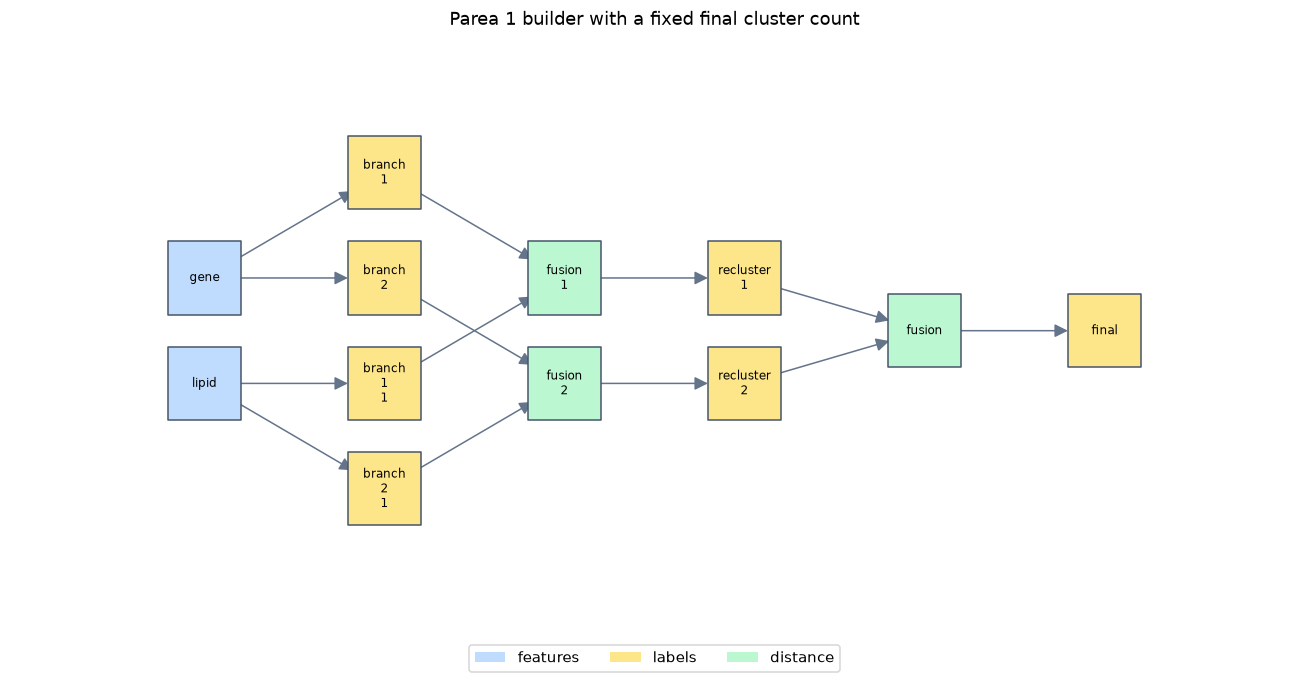

In [12]:
parea1 = models.parea_1(['gene', 'lipid'], methods=('ward', 'complete'),
                       n_clusters=3, k_final=2, return_matrix=True)
parea2 = models.parea_2(['gene', 'lipid'], methods=('ward', 'average'),
                       n_clusters=3, k_final=2, return_matrix=True)
parea1_result = parea1(**prepared_inputs)
parea2_result = parea2(**prepared_inputs)
assert parea1_result['labels'].shape == parea2_result['labels'].shape == (40,)
draw_workflow(parea1, 'Parea 1 builder with a fixed final cluster count')

## 9. Use agreement affinities with spectral clustering

Disagreement weights are distances: larger values mean more separation.
Agreement weights are affinities: larger values mean more similarity. Here we
fuse the same view partitions using agreement and connect the result to a
spectral block that explicitly accepts **precomputed affinities**.

A square matrix's shape alone does not tell us whether it represents distances
or affinities. The graph rejects an incompatible declared connection. A
partition-derived affinity graph can also be disconnected; the component count
below helps interpret a possible spectral-clustering warning.

In [13]:
affinity = nn.Fusion('agreement', normalize=True, name='agreement')(gene_labels, lipid_labels)
spectral_labels = nn.Cluster('spectral', input_kind=nn.AFFINITY, n_clusters=2,
                             random_state=SEED, name='spectral')(affinity)
spectral_graph = nn.Graph({'gene': gene_input, 'lipid': lipid_input},
                          {'labels': spectral_labels, 'affinity': affinity})
spectral_result = spectral_graph(**inputs)
print('Affinity graph components:',
      nx.number_connected_components(nx.from_numpy_array(spectral_result['affinity'])))
assert len(np.unique(spectral_result['labels'])) == 2

try:
    nn.Hierarchical(input_kind=nn.DISTANCE)(affinity)
except TypeError as error:
    print('Expected connection error:', error)
else:
    raise AssertionError('An affinity-to-distance mismatch should have been rejected')

Affinity graph components: 1
Expected connection error: Hierarchical port data expects ('distance',), received affinity


## 10. Start with a small parameter grid

`get_params()` exposes block configuration. `with_params()` makes an independent
configured graph for each trial, leaving the original unchanged. We will search
hierarchical linkage choices and a spectral alternative for the gene block,
along with the number of final clusters. Switching a generic `nn.Cluster` to a
different family starts from that family's defaults; the conditional grid supplies
its relevant parameters explicitly.

The objective is **label-free silhouette in a fixed evaluation geometry**:
standardize each original view, compute its Euclidean distances, scale them by
their positive median, then average the two matrices. The same evaluation
matrix is used for all candidates, so each view has comparable distance scale.

We deliberately do not select trials by genotype NMI or AMI. We also do not
optimize silhouette on each candidate's own fused matrix, whose construction
already encodes its partitions and can make the score look artificially high.
This grid provides a small reference search before the genetic example below.

In [14]:
view_distances = []
for frame in prepared_inputs.values():
    distance = pairwise_distances(frame, metric='euclidean')
    scale = np.median(distance[distance > 0])
    view_distances.append(distance / scale)
evaluation_distance = np.mean(view_distances, axis=0)
np.fill_diagonal(evaluation_distance, 0)
assert np.allclose(evaluation_distance, evaluation_distance.T)

def internal_score(labels):
    count = len(np.unique(labels))
    if not 1 < count < len(labels):
        return np.nan
    return silhouette_score(evaluation_distance, labels, metric='precomputed')

parameter_grid = list(ParameterGrid([
    {'gene_cluster__method': ['ward', 'average'],
     'lipid_cluster__method': ['complete', 'average'],
     'final__n_clusters': [2, 3, 4]},
    {'gene_cluster__clusterer': ['spectral'],
     'gene_cluster__affinity': ['rbf'],
     'gene_cluster__gamma': [0.005, 0.01],
     'gene_cluster__n_clusters': [2, 3],
     'gene_cluster__random_state': [SEED],
     'final__n_clusters': [2, 3, 4]},
]))
baseline_params = module_graph.get_params()
trials = []
for number, params in enumerate(parameter_grid):
    candidate = module_graph.with_params(**params)
    output = candidate(**inputs)
    score = internal_score(output['labels'])
    trials.append({'trial': number, 'params': params,
                   'clusters': len(np.unique(output['labels'])),
                   'view_silhouette': score, 'valid': bool(np.isfinite(score))})
assert module_graph.get_params() == baseline_params
search_results = pd.DataFrame(trials)
valid_trials = search_results.loc[search_results['valid']].sort_values(
    ['view_silhouette', 'trial'], ascending=[False, True], kind='mergesort')
assert not valid_trials.empty
best_trial = trials[int(valid_trials.iloc[0]['trial'])]
best_graph = module_graph.with_params(**best_trial['params'])
best_result = best_graph(**inputs)
assert np.isclose(internal_score(best_result['labels']), best_trial['view_silhouette'])
print('Completed {} trials: {} valid, {} degenerate'.format(
    len(trials), int(search_results['valid'].sum()), int((~search_results['valid']).sum())))
display(valid_trials.head(8).reset_index(drop=True))
display(pd.Series(best_trial['params'], name='Selected configuration'))

Completed 24 trials: 24 valid, 0 degenerate


,trial,params,clusters,view_silhouette,valid
0,19,"{'final__n_clusters': 3, 'gene_cluster__affini...",3,0.166524,True
1,1,"{'final__n_clusters': 2, 'gene_cluster__method...",2,0.166182,True
2,23,"{'final__n_clusters': 4, 'gene_cluster__affini...",4,0.165569,True
3,13,"{'final__n_clusters': 2, 'gene_cluster__affini...",2,0.135524,True
4,16,"{'final__n_clusters': 3, 'gene_cluster__affini...",3,0.125661,True
5,21,"{'final__n_clusters': 4, 'gene_cluster__affini...",4,0.125462,True
6,12,"{'final__n_clusters': 2, 'gene_cluster__affini...",2,0.125288,True
7,15,"{'final__n_clusters': 2, 'gene_cluster__affini...",2,0.120219,True


final__n_clusters                    3
gene_cluster__affinity             rbf
gene_cluster__clusterer       spectral
gene_cluster__gamma               0.01
gene_cluster__n_clusters             3
gene_cluster__random_state          42
Name: Selected configuration, dtype: object

## 11. Optimize the graph with a genetic algorithm

`optim.genetic_search()` accepts a compiled graph, aligned inputs, a search space
**grouped by block name**, and a fitness callable. Graph connectivity stays fixed.
The gene block has two conditional cases: hierarchical linkage choices or spectral
clustering with a log-uniform gamma. Crossover and mutation preserve each case's
active parameters, so hierarchical linkage is never passed to spectral clustering.
Integer domains include both bounds. The lipid linkage and final cluster count
are also optimized.

We reuse the fixed evaluation matrix from the grid example. Fitness receives the
graph's named-output dictionary and returns its silhouette score. The search seed
controls evolution; spectral clustering has its own seed. Score caching is enabled
because these operations and the objective are deterministic. Candidate errors or
nonfinite scores are recorded and penalized; if every candidate fails, search raises.

This example uses a different search space and evaluation budget from the grid,
including continuous gamma values. Their scores illustrate the API; this is not a
controlled comparison of genetic search against exhaustive search.

In [15]:
genetic_space = {
    'gene_cluster': [
        {'clusterer': 'hierarchical', 'method': ['ward', 'average'], 'n_clusters': 3},
        {'clusterer': 'spectral', 'affinity': 'rbf',
         'gamma': optim.Float(0.005, 0.01, log=True),
         'n_clusters': optim.Int(2, 3), 'random_state': SEED},
    ],
    'lipid_cluster': {'method': ['complete', 'average']},
    'final': {'n_clusters': optim.Int(2, 4)},
}
genetic = optim.genetic_search(
    module_graph, inputs, genetic_space,
    fitness=lambda output: internal_score(output['labels']),
    population_size=12, generations=5, random_state=SEED,
    crossover_probability=0.7, mutation_probability=0.3,
    on_error='penalize', cache=True,
)
genetic_output = genetic.best_graph(**inputs)
assert module_graph.get_params() == baseline_params
assert np.isclose(internal_score(genetic_output['labels']), genetic.best_score)
assert set(genetic.best_graph.graph.edges) == set(module_graph.graph.edges)
assert len(genetic.history) == 12 + 5 * (12 - 1)
print('Best observed fitness: {:.4f}'.format(genetic.best_score))
print('{} requests, {} actual evaluations, {} cache hits'.format(
    len(genetic.history), genetic.n_evaluations,
    sum(row['cached'] for row in genetic.history)))
display(pd.Series(genetic.best_params, name='Genetic selection'))
genetic_history = pd.DataFrame(genetic.history)
display(genetic_history[['generation', 'score', 'status', 'cached', 'phase', 'error']].head(10))

Best observed fitness: 0.1662
67 requests, 18 actual evaluations, 49 cache hits


gene_cluster__clusterer       spectral
gene_cluster__affinity             rbf
gene_cluster__gamma            0.00838
gene_cluster__n_clusters             3
gene_cluster__random_state          42
lipid_cluster__method          average
final__n_clusters                    2
Name: Genetic selection, dtype: object

,generation,score,status,cached,phase,error
0,0,0.066895,ok,False,None,None
1,0,0.099604,ok,False,None,None
2,0,0.027434,ok,False,None,None
3,0,0.153706,ok,False,None,None
4,0,0.127290,ok,False,None,None
5,0,0.106743,ok,False,None,None
6,0,0.122153,ok,False,None,None
7,0,0.127290,ok,False,None,None
8,0,0.107390,ok,False,None,None
9,0,0.027434,ok,True,None,None


### Inspect evolution and reuse the selected graph

The generation log includes the initial population (generation zero). Elitism
retains the best observed configuration. `best_params` contains active overrides
in the usual `block__parameter` format; `best_graph` is a separate configured copy,
ready to execute on aligned data. Actual evaluation counts exclude cached scores
and elites carried forward. The score is an observed optimum within this search,
with no guarantee of finding the global optimum.

,generation,evaluations,cache_hits,valid,failed,generation_best,best_score,mean_score
0,0,11,1,12,0,0.166182,0.166182,0.103970
1,1,3,8,12,0,0.166182,0.166182,0.145467
2,2,2,9,12,0,0.166182,0.166182,0.150789
3,3,2,9,12,0,0.166182,0.166182,0.147282
4,4,0,11,12,0,0.166182,0.166182,0.165142
5,5,0,11,12,0,0.166182,0.166182,0.166182


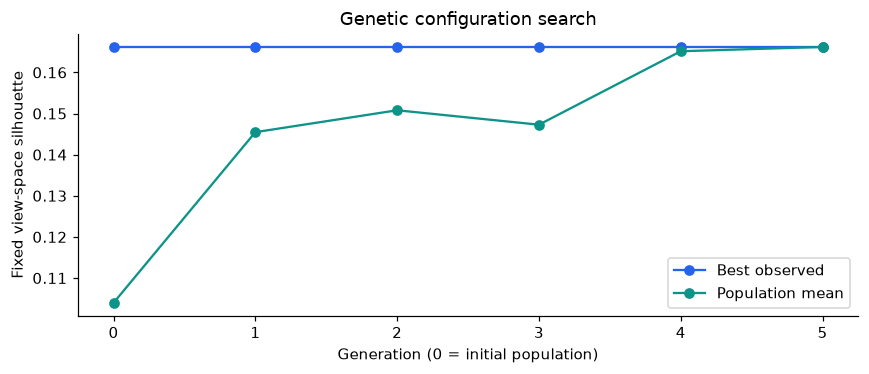

In [16]:
evolution = pd.DataFrame(genetic.logbook)
assert evolution['best_score'].is_monotonic_increasing
display(evolution)
ax = evolution.plot(x='generation', y=['best_score', 'mean_score'], marker='o',
                    figsize=(8, 3.5), color=['#2563eb', '#0d9488'])
ax.set(xlabel='Generation (0 = initial population)', ylabel='Fixed view-space silhouette',
       title='Genetic configuration search')
ax.legend(['Best observed', 'Population mean'])
plt.tight_layout()
plt.show()

reconstructed = module_graph.with_params(**genetic.best_params)
assert np.array_equal(reconstructed(**inputs)['labels'], genetic_output['labels'])

## 12. Evaluate the completed runs against genotype

Now we bring in the genotype annotations. NMI (normalized mutual information)
and AMI (adjusted mutual information) compare partitions without relying on the
numeric names of their clusters. Neither metric was used in either search above.

Every row below is computed from this execution on the same 40 mice. No historical
best scores are copied from the old notebook. The custom strict-consensus graph
may produce more than two clusters, so this is an illustration of behavior, not
a controlled benchmark establishing that one topology is superior.

,clusters,view_silhouette,NMI_genotype,AMI_genotype
model,,,,
Functional graph,2,0.1067,0.1520,0.1358
Module graph,2,0.1067,0.1520,0.1358
Custom stacked graph,4,0.1452,0.0211,-0.0196
Parea 1 builder,2,0.0944,0.0000,-0.0216
Parea 2 builder,2,0.1662,0.0179,-0.0074
Spectral affinity graph,2,0.1000,0.0018,-0.0173
Selected grid trial,3,0.1665,0.0000,-0.0314
Selected genetic trial,2,0.1662,0.0179,-0.0074


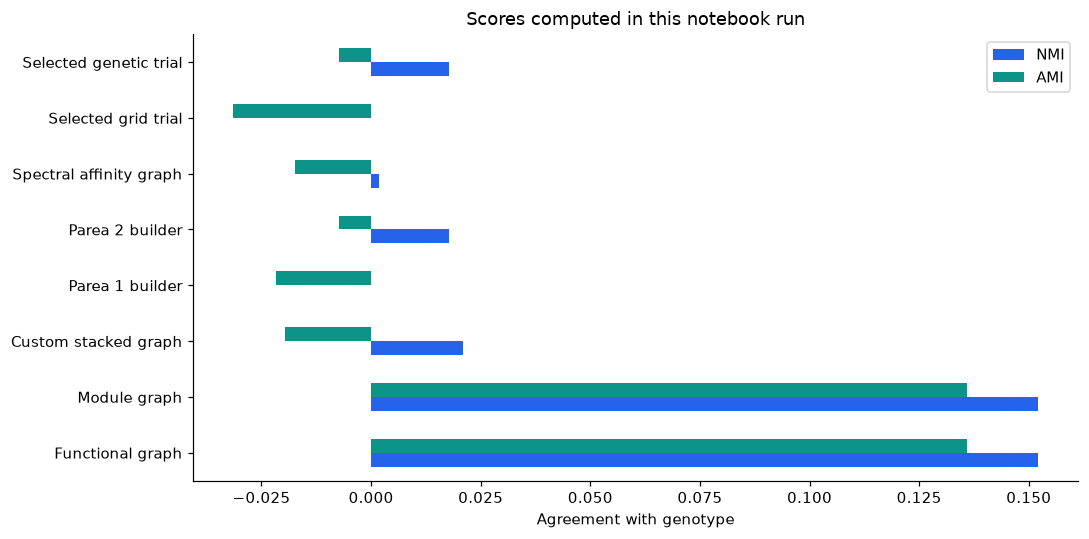

In [17]:
partitions = {
    'Functional graph': functional_result['labels'],
    'Module graph': module_result['labels'],
    'Custom stacked graph': stacked_result['labels'],
    'Parea 1 builder': parea1_result['labels'],
    'Parea 2 builder': parea2_result['labels'],
    'Spectral affinity graph': spectral_result['labels'],
    'Selected grid trial': best_result['labels'],
    'Selected genetic trial': genetic_output['labels'],
}
summary = pd.DataFrame([
    {'model': name, 'clusters': len(np.unique(labels)),
     'view_silhouette': internal_score(labels),
     'NMI_genotype': normalized_mutual_info_score(genotype, labels),
     'AMI_genotype': adjusted_mutual_info_score(genotype, labels)}
    for name, labels in partitions.items()
]).set_index('model')
assert np.isfinite(summary[['view_silhouette', 'NMI_genotype', 'AMI_genotype']]).all().all()
display(summary.round(4))

ax = summary[['NMI_genotype', 'AMI_genotype']].plot.barh(
    figsize=(10, 5), color=['#2563eb', '#0d9488'])
ax.set(xlabel='Agreement with genotype', ylabel='',
       title='Scores computed in this notebook run')
ax.legend(['NMI', 'AMI'])
plt.tight_layout()
plt.show()

### Read the scores in context

A higher internal silhouette score does not necessarily improve agreement with
genotype. Both searches optimize compactness in the fixed view-space
geometry, while NMI and AMI assess agreement with one external annotation.
Negative AMI values are possible after chance correction. These examples show
how to construct and evaluate workflows; they do not establish a new benchmark
result or reproduce the original notebook's best scores.

### Inspect a fused matrix and its selected partition

The graph selected by the grid exposes the pairwise distances created by its fusion block.
Ordering samples by its predicted labels makes the block structure visible.
The second matrix shows the separate, fixed view-space geometry used for search.
Their scales and interpretations differ; a clean fused block pattern alone is
not evidence of agreement with a biological annotation.

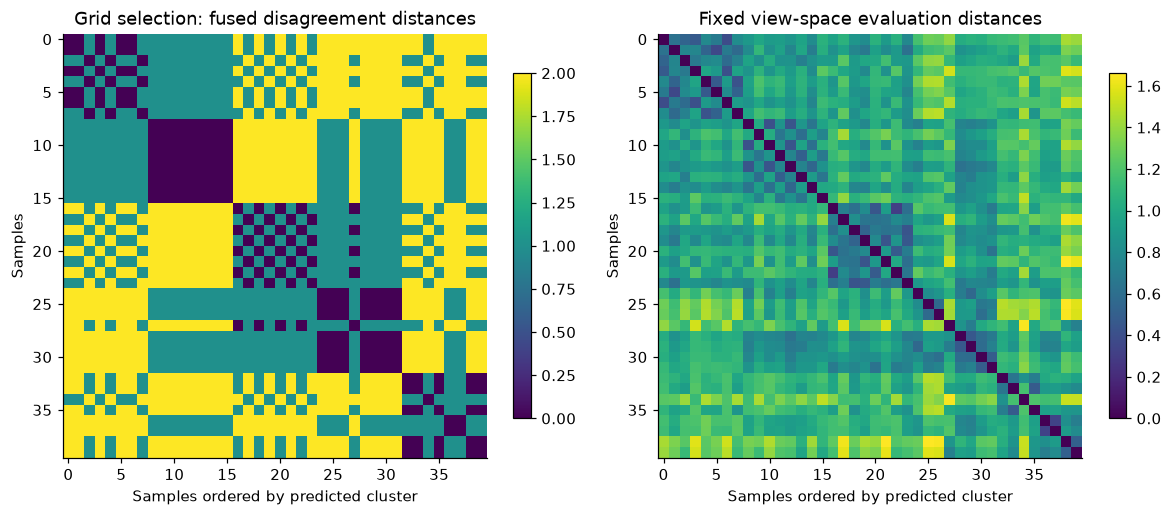

cluster,0,1,2
genotype,,,
ppar,8,8,4
wt,8,8,4


Notebook completed: 2 views, 40 samples, 24 grid trials, 18 genetic evaluations, 8 evaluated partitions.


In [18]:
order = np.argsort(best_result['labels'], kind='stable')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, matrix, title in zip(
    axes, [best_result['distance'], evaluation_distance],
    ['Grid selection: fused disagreement distances', 'Fixed view-space evaluation distances'],
):
    image = ax.imshow(matrix[np.ix_(order, order)], cmap='viridis', interpolation='nearest')
    ax.set(title=title, xlabel='Samples ordered by predicted cluster', ylabel='Samples')
    fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

display(pd.crosstab(genotype, pd.Series(best_result['labels'], index=sample_ids, name='cluster')))
print('Notebook completed: {} views, {} samples, {} grid trials, '
      '{} genetic evaluations, {} evaluated partitions.'.format(
    len(inputs), len(gene), len(trials), genetic.n_evaluations, len(partitions)))

## What to change next

- Add another `nn.Input` and its preprocessing/clustering branch for a new view.
- Connect the same symbolic result to several blocks to share intermediate work.
- Build reusable submodules and call them from a larger module's `forward()`.
- Replace a leaf operation with a custom `nn.Block` or `nn.Function`.
- Extend the conditional genetic search space, keeping selection separate from evaluation labels.
- Inspect `model.graph` with NetworkX; rebuild the symbolic topology when changing connections.

The graph API executes DAGs sequentially in dependency order. It supports arbitrary
branching and layering, but cycles and automated topology search are not included.
The parameter exercise uses the same data for clustering and internal scoring;
external replication or stability analysis would be needed for stronger scientific
claims. The dataset contains 40 mice, not cancer patients.

## References

- [Original Pyrea Nutrimouse notebook](Nutrimouse.ipynb).
- Pfeifer, Bloice and Schimek (2023), *Parea: Multi-view ensemble clustering for
  cancer subtype discovery*. https://doi.org/10.1016/j.jbi.2023.104406
- Martin et al. (2007), *Novel aspects of PPARalpha-mediated regulation of lipid
  and xenobiotic metabolism revealed through a nutrigenomic study*.
  https://doi.org/10.1002/hep.21510
- Gonzalez et al. (2008), *CCA: An R Package to Extend Canonical Correlation Analysis*.
  https://doi.org/10.18637/jss.v023.i12
- [Bundled dataset provenance and attribution](data/nutrimouse/README.md).
- [Graph API guide](../docs/source/graphs.rst).